# Laboratorio 10: Explicabilidad en visión con Grad-CAM y CAM

Este notebook explica las decisiones de un ResNet-18 preentrenado en ImageNet. Primero se implementa Grad-CAM desde cero y se verifica numéricamente su relación con CAM (Task 1). Después se pone a prueba si esos mapas merecen confianza con las métricas de deletion e insertion y con la prueba de aleatorización de parámetros en cascada (Task 4).

Las funciones reutilizables se encuentran en `src/vision/`. El notebook está pensado para ejecutarse en Google Colab, en CPU.

## Configuración

La siguiente celda clona el repositorio cuando el notebook se ejecuta en Colab y agrega su carpeta raíz al `sys.path` para poder importar los módulos de `src/`.

In [1]:
import os
import sys

REPO_URL = "https://github.com/Tunchxz/CC3092-Laboratorio-10.git"
ROOT = "/content/CC3092-Laboratorio-10"

if "google.colab" in sys.modules:
    if not os.path.isdir(ROOT):
        !git clone -q {REPO_URL} {ROOT}
else:
    ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

In [2]:
import copy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from src.vision.images import draw_box, gray_like, load_image, load_resnet18, predict_proba, show_overlay, top_k
from src.vision.gradcam import cam_from_fc, grad_cam, iou, min_max, top_fraction_mask
from src.vision.faithfulness import (CASCADE_STAGES, blurred_like, cascading_randomization,
                                     deletion_insertion, faithfulness_scores, reset_module)

SEED = 42
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
pd.set_option("display.float_format", lambda v: f"{v:.6g}")
print(f"Semilla aleatoria: {SEED} | PyTorch {torch.__version__}")

Semilla aleatoria: 42 | PyTorch 2.11.0+cpu


## Task 1 - Grad-CAM y CAM

### Task 1.1. Modelo, imágenes y predicciones

Se carga el ResNet-18 con los pesos de ImageNet en modo de evaluación. Cada imagen se redimensiona a 256 píxeles en el lado corto, se recorta al centro a 224 por 224 y se normaliza por canal con la media $(0.485, 0.456, 0.406)$ y la desviación estándar $(0.229, 0.224, 0.225)$ de ImageNet.

Las tres imágenes provienen de Wikimedia Commons.

| Caso | Imagen | Autor | Fuente |
| :--: | :----- | :---- | :----- |
| (a) | Jilguero, objeto claro y centrado | Francis C. Franklin | [Carduelis carduelis close up](https://commons.wikimedia.org/wiki/File:Carduelis_carduelis_close_up.jpg) |
| (b) | Gato siamés y perro, dos clases distintas | Arantz | [Cat and dog](https://commons.wikimedia.org/wiki/File:Cat_and_dog.JPG) |
| (c) | Vaca en la playa, objeto fuera de su contexto habitual | Timothy A. Gonsalves | [Cow Uthandi Beach Chennai](https://commons.wikimedia.org/wiki/File:Cow_Uthandi_Beach_Chennai_Aug21_D72_20734.jpg) |

In [3]:
model, categories = load_resnet18()

IMG_DIR = os.path.join(ROOT, "data", "raw", "images")
IMAGES = {"a": "a_objeto.jpg", "b": "b_dos_objetos.jpg", "c": "c_fuera_contexto.jpg"}
BOX_C = (14, 68, 154, 208)  # (x0, y0, x1, y1) del objeto en la imagen (c) de 224 x 224

inputs, rgbs = {}, {}
for key, name in IMAGES.items():
    inputs[key], rgbs[key] = load_image(os.path.join(IMG_DIR, name))
    print(f"Imagen ({key}): tensor {tuple(inputs[key].shape)}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 35.4MB/s]


Imagen (a): tensor (1, 3, 224, 224)
Imagen (b): tensor (1, 3, 224, 224)
Imagen (c): tensor (1, 3, 224, 224)


In [4]:
top5 = {key: top_k(model, inputs[key], categories, k=5) for key in IMAGES}
rows = [
    {"imagen": key, "posición": pos, "índice": idx, "clase": name, "probabilidad": prob}
    for key, preds in top5.items()
    for pos, (idx, name, prob) in enumerate(preds, start=1)
]
pd.DataFrame(rows).set_index(["imagen", "posición"])

índice                clase  probabilidad
imagen posición                                           
a      1             11            goldfinch      0.998227
       2             10            brambling    0.00109786
       3             92            bee eater   0.000267304
       4             16               bulbul   5.79559e-05
       5             93             hornbill    5.1006e-05
b      1            273                dingo      0.703734
       2            225             malinois     0.0552382
       3            253              basenji     0.0455503
       4            227               kelpie     0.0430067
       5            159  Rhodesian ridgeback     0.0355609
c      1            345                   ox      0.453344
       2            690               oxcart      0.335339
       3            273                dingo     0.0234456
       4            978             seashore     0.0119168
       5            208   Labrador retriever     0.0118014

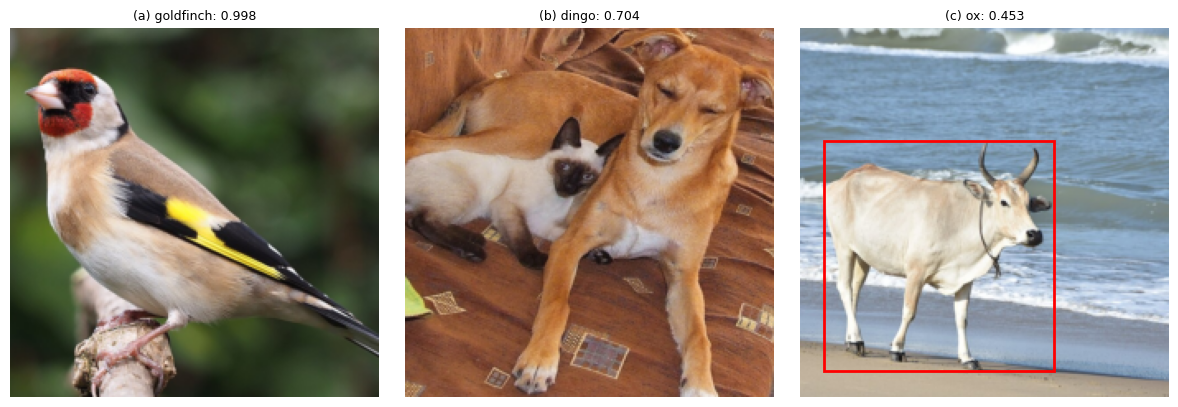

Recuadro del objeto en (c): x0=14, y0=68, x1=154, y1=208 (140 x 140 píxeles, 39.1% de la imagen)


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, key in zip(axes, IMAGES):
    ax.imshow(rgbs[key])
    ax.set_title(f"({key}) {top5[key][0][1]}: {top5[key][0][2]:.3f}", fontsize=9)
    ax.axis("off")
draw_box(axes[2], BOX_C, color="red")
plt.tight_layout()
plt.show()

x0, y0, x1, y1 = BOX_C
print(f"Recuadro del objeto en (c): x0={x0}, y0={y0}, x1={x1}, y1={y1} "
      f"({x1 - x0} x {y1 - y0} píxeles, {(x1 - x0) * (y1 - y0) / 224**2:.1%} de la imagen)")

**RESULTADOS**

En la imagen (a) el modelo asigna 0.998 a `goldfinch`, por lo que el objeto se reconoce sin ambigüedad. En la imagen (b) la clase principal es `dingo` (0.704) y las otras cuatro también son razas de perro, de modo que el gato siamés no aparece entre las cinco primeras. En la imagen (c) la clase principal es `ox` (0.453), seguida de `oxcart` (0.335), y en cuarto lugar aparece `seashore` (0.012), una clase del fondo. El recuadro de la vaca en la imagen de 224 por 224 es $(x_0, y_0, x_1, y_1) = (14, 68, 154, 208)$ y cubre el 39.1% de la imagen.

### Task 1.2. Grad-CAM desde cero

La función `grad_cam` de `src/vision/gradcam.py` registra dos hooks sobre `layer4`. El hook de avance guarda las activaciones $A$ (512 canales de 7 por 7) y el hook de retroceso guarda $\frac{\partial y^{c}}{\partial A}$. El gradiente se retropropaga desde el logit $y^{c}$, antes del softmax. Luego se calculan

$$a_{k}^{c} = \frac{1}{Z}\sum_{i,j}\frac{\partial y^{c}}{\partial A_{ij}^{k}}, \qquad L^{c} = \operatorname{ReLU}\Big(\sum_{k} a_{k}^{c} A^{k}\Big),$$

y el mapa se amplía a 224 por 224 con interpolación bilineal y se normaliza con su mínimo y su máximo.

Para la imagen (b) se explica también la clase del segundo objeto. Si la clase principal es un cánido (índices 151 a 280 de ImageNet, que incluyen perros domésticos y salvajes como el dingo), se toma la clase de gato doméstico (índices 281 a 285) de mayor probabilidad, y viceversa.

In [6]:
top1 = {key: top5[key][0][0] for key in IMAGES}

DOG_CLASSES = range(151, 281)
CAT_CLASSES = range(281, 286)
probs_b = predict_proba(model, inputs["b"])[0]
second_group = CAT_CLASSES if top1["b"] in DOG_CLASSES else DOG_CLASSES
second_b = max(second_group, key=lambda i: probs_b[i].item())
print(f"Imagen (b): clase principal = {categories[top1['b']]} ({probs_b[top1['b']]:.3f}), "
      f"segundo objeto = {categories[second_b]} ({probs_b[second_b]:.3f})")

cams = {key: grad_cam(model, model.layer4, inputs[key], top1[key]) for key in IMAGES}
cam_b2 = grad_cam(model, model.layer4, inputs["b"], second_b)
print(f"Activaciones A: {cams['a'].activations.shape}, gradientes: {cams['a'].gradients.shape}")

Imagen (b): clase principal = dingo (0.704), segundo objeto = Siamese cat (0.000)
Activaciones A: (512, 7, 7), gradientes: (512, 7, 7)


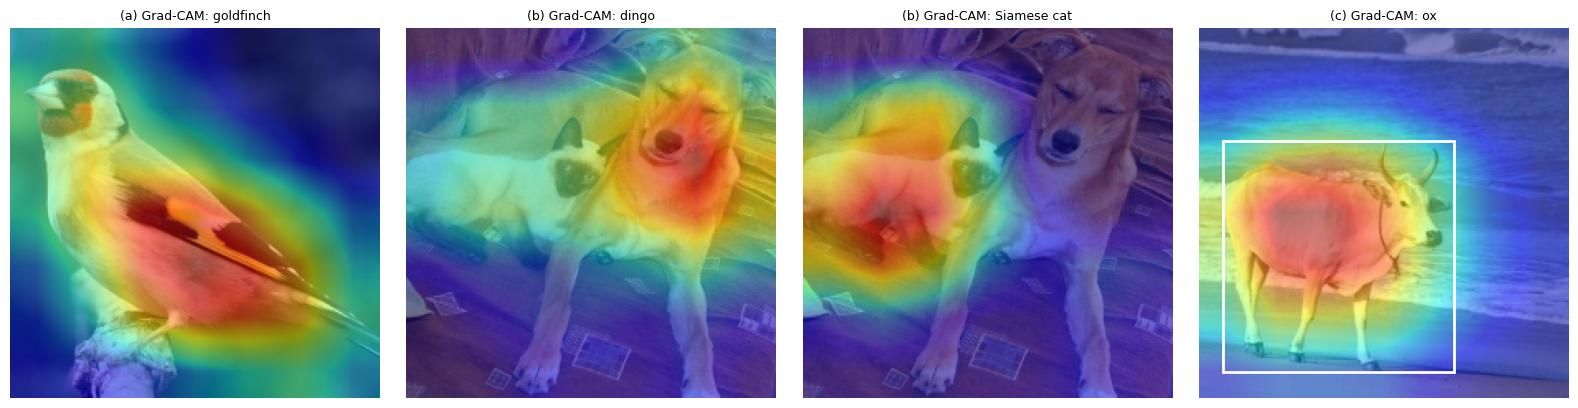

In [7]:
panels = [
    ("a", cams["a"], top1["a"], None),
    ("b", cams["b"], top1["b"], None),
    ("b", cam_b2, second_b, None),
    ("c", cams["c"], top1["c"], BOX_C),
]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (key, res, cls, box) in zip(axes, panels):
    show_overlay(ax, rgbs[key], res.heatmap, title=f"({key}) Grad-CAM: {categories[cls]}", box=box)
plt.tight_layout()
plt.show()

**RESULTADOS**

En la imagen (a) el mapa se concentra en el cuerpo y el ala del jilguero. En la imagen (b) el mapa de `dingo` cae sobre la cabeza del perro y el de `Siamese cat` cae sobre el gato, aunque la probabilidad de esa clase es menor que 0.001. Grad-CAM localiza la evidencia de una clase aunque el modelo no la elija. En la imagen (c) el mapa de `ox` se concentra en el cuerpo de la vaca, dentro del recuadro.

### Task 1.3. CAM desde los pesos de la capa final

El ResNet-18 termina en pooling global promedio y una capa lineal `fc`, por lo que el logit se descompone espacialmente. Con los pesos $w_{k}^{c}$ de `fc` se calcula, sin gradientes,

$$M_{ij}^{c} = \sum_{k} w_{k}^{c} A_{ij}^{k}, \qquad y^{c} = \frac{1}{Z}\sum_{i,j} M_{ij}^{c} + b_{c}, \qquad Z = 49.$$

La tabla reporta, para cada imagen, la descomposición del puntaje, el error máximo entre $Z \cdot L^{c}$ (sin ReLU ni normalización) y $M^{c}$, y el error máximo entre ambos mapas después de aplicar ReLU y normalización mínimo-máximo.

In [8]:
Z = 49
rows = []
cam_maps = {}
for key in IMAGES:
    res = cams[key]
    M, bias = cam_from_fc(model.fc, res.activations, top1[key])
    cam_maps[key] = M
    score = M.sum() / Z + bias
    rows.append({
        "imagen": key,
        "clase": categories[top1[key]],
        "logit y^c": res.logit,
        "sum(M)/Z + b": score,
        "error puntaje": abs(score - res.logit),
        "max |Z·L - M|": np.abs(Z * res.raw - M).max(),
        "max error ReLU + min-max": np.abs(min_max(res.cam) - min_max(np.maximum(M, 0))).max(),
    })
pd.DataFrame(rows).set_index("imagen")

,clase,logit y^c,sum(M)/Z + b,error puntaje,max |Z·L - M|,max error ReLU + min-max
imagen,,,,,,
a,goldfinch,17.6802,17.6802,3.8147e-06,1.52588e-05,5.70003e-07
b,dingo,13.1228,13.1228,9.53674e-07,1.71661e-05,6.50841e-07
c,ox,10.335,10.335,9.53674e-07,1.90735e-05,5.43121e-07


**RESULTADOS**

En las tres imágenes, $\frac{1}{Z}\sum_{i,j}M_{ij}^{c} + b_{c}$ reproduce el logit con un error absoluto de $3.8 \times 10^{-6}$ como máximo, y $Z \cdot L^{c}$ coincide con $M^{c}$ con un error máximo de $1.9 \times 10^{-5}$ sobre las 49 posiciones. Después de aplicar ReLU y normalización, la diferencia máxima entre ambos mapas es menor que $6.6 \times 10^{-7}$. En este ResNet-18, Grad-CAM y CAM producen el mismo mapa salvo el factor $Z$.

### Task 1.4. Análisis con los resultados

#### 1.4.1. Pesos de Grad-CAM frente a pesos de `fc`

Se comparan los $a_{k}^{c}$ obtenidos con gradientes y los valores $\frac{w_{k}^{c}}{Z}$ para los cinco canales de mayor peso de la clase de la imagen (a).

In [9]:
res_a = cams["a"]
w_a = model.fc.weight.detach()[top1["a"]].numpy()
channels = np.argsort(-w_a)[:5]
pd.DataFrame({
    "canal k": channels,
    "w_k": w_a[channels],
    "a_k (gradiente)": res_a.alpha[channels],
    "w_k / Z": w_a[channels] / Z,
    "error relativo": np.abs(res_a.alpha[channels] - w_a[channels] / Z) / np.abs(w_a[channels] / Z),
}).set_index("canal k")

,w_k,a_k (gradiente),w_k / Z,error relativo
canal k,,,,
141,0.391743,0.00799476,0.00799476,1.16492e-07
178,0.358326,0.00731278,0.00731278,1.91033e-07
203,0.297881,0.0060792,0.0060792,1.53198e-07
17,0.289172,0.00590148,0.00590148,0
100,0.266684,0.00544254,0.00544254,8.55596e-08


In [10]:
print(f"Épsilon de máquina en float32: {np.finfo(np.float32).eps:.3e}")
print(f"Tipo de dato de los gradientes: {res_a.gradients.dtype}")
print(f"Desviación estándar espacial máxima del gradiente entre canales: {res_a.gradients.std(axis=(1, 2)).max():.3e}")

Épsilon de máquina en float32: 1.192e-07
Tipo de dato de los gradientes: float32
Desviación estándar espacial máxima del gradiente entre canales: 4.657e-10


**Respuesta**

Para los cinco canales de mayor peso de `goldfinch`, $a_{k}^{c}$ coincide con $\frac{w_{k}^{c}}{Z}$ con errores relativos entre 0 y $1.9 \times 10^{-7}$.

La derivación vista en clase parte de $y^{c} = \sum_{k} w_{k}^{c} \frac{1}{Z}\sum_{i,j}A_{ij}^{k} + b_{c}$. Al derivar se obtiene $\frac{\partial y^{c}}{\partial A_{ij}^{k}} = \frac{w_{k}^{c}}{Z}$, que no depende de la posición $(i, j)$. Ese hecho se usa al calcular el promedio espacial del gradiente, porque el promedio de 49 valores iguales es ese mismo valor, $a_{k}^{c} = \frac{1}{Z}\sum_{i,j}\frac{w_{k}^{c}}{Z} = \frac{w_{k}^{c}}{Z}$. La salida lo confirma, ya que la desviación estándar espacial del gradiente en cada canal es a lo sumo $4.7 \times 10^{-10}$.

Los errores no son exactamente cero porque todo el cálculo se hace en `float32`, cuyo épsilon de máquina es $1.19 \times 10^{-7}$. El gradiente se obtiene al dividir $w_{k}^{c}$ entre 49 dentro del backward del pooling y luego se promedian 49 copias, mientras que $\frac{w_{k}^{c}}{Z}$ se calcula con una sola división. Cada camino redondea en pasos distintos y los resultados difieren en una o dos unidades del último dígito representable, que es el orden de los errores relativos observados.

#### 1.4.2. Discriminación entre las dos clases de la imagen (b)

Se toma, en cada mapa ampliado, el conjunto del 20% de píxeles de mayor valor y se calcula la intersección sobre la unión (IoU) entre ambos conjuntos.

IoU entre los conjuntos del 20% (dingo vs Siamese cat): 0.0000


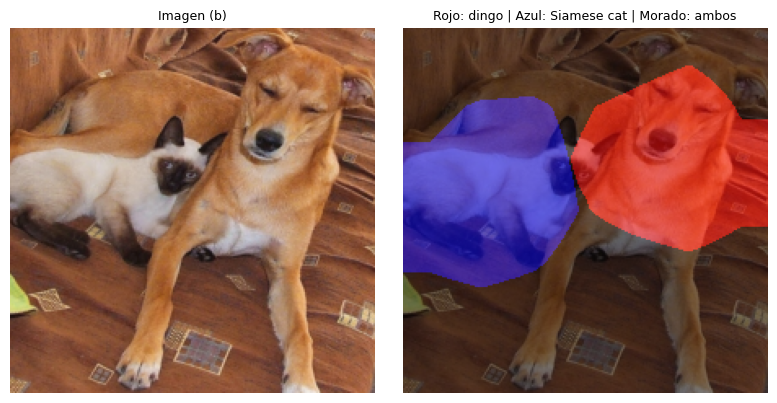

In [11]:
mask_1 = top_fraction_mask(cams["b"].heatmap, 0.2)
mask_2 = top_fraction_mask(cam_b2.heatmap, 0.2)
print(f"IoU entre los conjuntos del 20% ({categories[top1['b']]} vs {categories[second_b]}): {iou(mask_1, mask_2):.4f}")

overlap = np.zeros((224, 224, 3))
overlap[mask_1] += [1, 0, 0]
overlap[mask_2] += [0, 0, 1]
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(rgbs["b"])
axes[0].set_title("Imagen (b)", fontsize=9)
axes[1].imshow(rgbs["b"])
axes[1].imshow(overlap, alpha=0.5)
axes[1].set_title(f"Rojo: {categories[top1['b']]} | Azul: {categories[second_b]} | Morado: ambos", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Respuesta**

El IoU entre los conjuntos del 20% de mayor valor de `dingo` y de `Siamese cat` es 0.0000, es decir, los conjuntos no comparten ningún píxel. El mapa sí discrimina entre las dos clases, ya que la evidencia de `dingo` está en la cabeza del perro y la de `Siamese cat` en el cuerpo del gato.

Cada posición del mapa de 7 por 7 resume un bloque de 32 por 32 píxeles de la entrada, y la interpolación bilineal solo suaviza esos bloques sin agregar detalle. Por eso un objeto menor que unos 32 píxeles ocupa a lo sumo una celda y su evidencia se mezcla con la de su entorno, y dos objetos separados por menos de una celda caen en las mismas posiciones y no se pueden distinguir. En esta imagen la separación funciona porque el gato y el perro ocupan varias celdas cada uno, pero aun así el borde entre ambos conjuntos sigue la forma poligonal de la cuadrícula y no el contorno real de los animales.

#### 1.4.3. Masa del mapa dentro del recuadro y prueba causal en la imagen (c)

Se calcula la fracción de la masa del mapa normalizado que cae dentro del recuadro del objeto. Después se reemplaza por gris medio todo lo que queda fuera del recuadro y se mide el cambio en la probabilidad de la clase.

Fracción de la masa del mapa dentro del recuadro: 0.7410
Fracción del área de la imagen que ocupa el recuadro: 0.3906

Probabilidad de 'ox' con la imagen original: 0.4533
Probabilidad con el fondo reemplazado por gris:        0.3229
Cambio: -0.1304

Top-5 con el fondo en gris:
  oxcart                    0.4247
  ox                        0.3229
  dingo                     0.1141
  ibex                      0.0095
  muzzle                    0.0078


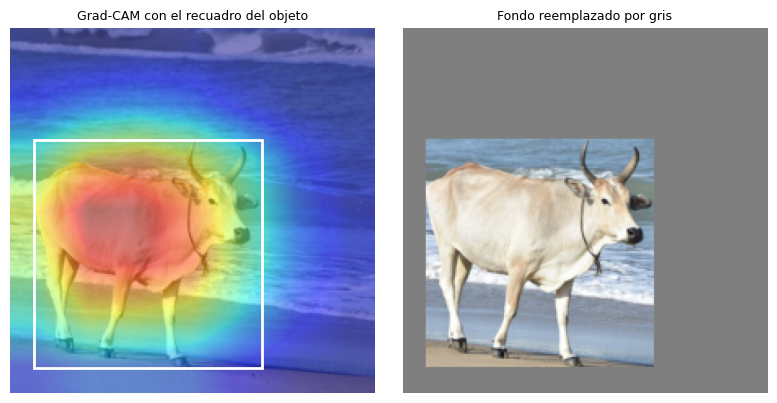

In [12]:
heat_c = cams["c"].heatmap
x0, y0, x1, y1 = BOX_C
mass_inside = heat_c[y0:y1, x0:x1].sum() / heat_c.sum()
area_inside = (x1 - x0) * (y1 - y0) / heat_c.size
print(f"Fracción de la masa del mapa dentro del recuadro: {mass_inside:.4f}")
print(f"Fracción del área de la imagen que ocupa el recuadro: {area_inside:.4f}")

outside = torch.ones(1, 1, 224, 224)
outside[..., y0:y1, x0:x1] = 0
x_box_only = inputs["c"] * (1 - outside) + gray_like(inputs["c"]) * outside

p_original = predict_proba(model, inputs["c"])[0, top1["c"]].item()
p_box_only = predict_proba(model, x_box_only)[0, top1["c"]].item()
print(f"\nProbabilidad de '{categories[top1['c']]}' con la imagen original: {p_original:.4f}")
print(f"Probabilidad con el fondo reemplazado por gris:        {p_box_only:.4f}")
print(f"Cambio: {p_box_only - p_original:+.4f}")
print("\nTop-5 con el fondo en gris:")
for idx, name, prob in top_k(model, x_box_only, categories):
    print(f"  {name:<25} {prob:.4f}")

box_only_rgb = (x_box_only[0].permute(1, 2, 0).numpy() * np.array([0.229, 0.224, 0.225])
                + np.array([0.485, 0.456, 0.406])).clip(0, 1)
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
show_overlay(axes[0], rgbs["c"], heat_c, title="Grad-CAM con el recuadro del objeto", box=BOX_C)
axes[1].imshow(box_only_rgb)
axes[1].set_title("Fondo reemplazado por gris", fontsize=9)
axes[1].axis("off")
plt.tight_layout()
plt.show()

**Respuesta**

El 74.1% de la masa del mapa cae dentro del recuadro, que ocupa solo el 39.1% de la imagen, por lo que el mapa indica que el modelo se apoya sobre todo en la vaca. En la prueba causal, al reemplazar por gris todo lo que queda fuera del recuadro, la probabilidad de `ox` baja de 0.4533 a 0.3229 (cambio de -0.1304) y `oxcart` pasa al primer lugar con 0.4247.

El mapa y la prueba causal coinciden. El modelo usa el fondo en parte, ya que el 25.9% de la masa queda fuera del recuadro y quitar el fondo reduce la probabilidad de `ox` en un 29% relativo. Sin embargo, la vaca por sí sola sigue llevando la predicción hacia clases bovinas, porque `ox` y `oxcart` suman 0.75 sin fondo frente a 0.79 con fondo. No hay evidencia de un atajo, ya que el modelo no depende de la playa para reconocer al animal. Una parte de la caída puede deberse al propio parche gris, que también es una entrada artificial.

## Task 4 - ¿Merecen confianza los mapas?

### Task 4.1. Deletion e insertion

Los píxeles de la imagen de 224 por 224 se ordenan según el valor del mapa de Grad-CAM, de mayor a menor. En $P = 20$ pasos se modifica la fracción $\frac{k}{P}$ de los píxeles más importantes y se registra la probabilidad $c_{k}$ de la clase de mayor probabilidad.

- **Deletion** reemplaza esos píxeles por gris medio. Un buen mapa hace caer la probabilidad rápido, por lo que se espera un $\operatorname{AUC}_{\text{del}}$ bajo.
- **Insertion** parte de la imagen desenfocada con un filtro gaussiano de $\sigma = 10$ píxeles y copia esos píxeles desde la original. Un buen mapa hace subir la probabilidad rápido, por lo que se espera un $\operatorname{AUC}_{\text{ins}}$ alto.

En ambos casos $\operatorname{AUC} = \frac{1}{P}\sum_{k=1}^{P} c_{k}$. Como referencia se repite el cálculo con 10 órdenes aleatorios de los píxeles.

In [13]:
faith = {key: deletion_insertion(model, inputs[key], cams[key].heatmap, top1[key], rng,
                                 n_random=10, steps=20, blur_sigma=10.0)
         for key in IMAGES}

for key in IMAGES:
    rows = []
    for metric in ("deletion", "insertion"):
        r = faith[key][metric]
        rows.append({
            "métrica": metric,
            "AUC Grad-CAM": r["auc"],
            "AUC azar (media)": r["random_aucs"].mean(),
            "AUC azar (desv. est.)": r["random_aucs"].std(ddof=1),
            "diferencia (Grad-CAM - azar)": r["auc"] - r["random_aucs"].mean(),
        })
    print(f"Imagen ({key}) · clase '{categories[top1[key]]}'")
    display(pd.DataFrame(rows).set_index("métrica"))

Imagen (a) · clase 'goldfinch'


,AUC Grad-CAM,AUC azar (media),AUC azar (desv. est.),diferencia (Grad-CAM - azar)
métrica,,,,
deletion,0.125361,0.388451,0.0469037,-0.26309
insertion,0.956791,0.360987,0.03874,0.595804


Imagen (b) · clase 'dingo'


,AUC Grad-CAM,AUC azar (media),AUC azar (desv. est.),diferencia (Grad-CAM - azar)
métrica,,,,
deletion,0.0466321,0.130211,0.0130338,-0.083579
insertion,0.579112,0.172675,0.0176212,0.406437


Imagen (c) · clase 'ox'


,AUC Grad-CAM,AUC azar (media),AUC azar (desv. est.),diferencia (Grad-CAM - azar)
métrica,,,,
deletion,0.00467335,0.0152601,0.00633494,-0.0105868
insertion,0.379856,0.0679681,0.0105616,0.311888


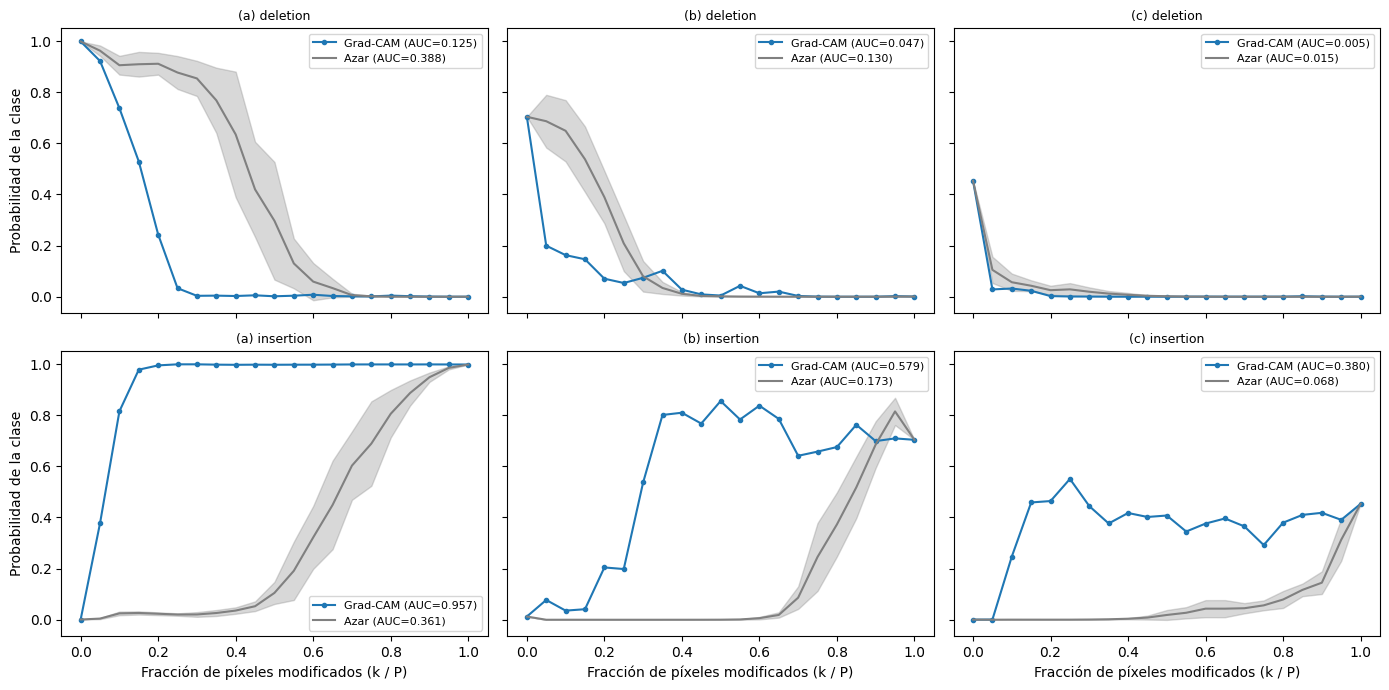

In [14]:
fractions = np.linspace(0, 1, 21)
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True, sharey=True)
for col, key in enumerate(IMAGES):
    for row, metric in enumerate(("deletion", "insertion")):
        ax = axes[row, col]
        r = faith[key][metric]
        mean, std = r["random_curves"].mean(axis=0), r["random_curves"].std(axis=0, ddof=1)
        ax.plot(fractions, r["curve"], marker="o", ms=3, label=f"Grad-CAM (AUC={r['auc']:.3f})")
        ax.plot(fractions, mean, color="gray", label=f"Azar (AUC={r['random_aucs'].mean():.3f})")
        ax.fill_between(fractions, mean - std, mean + std, color="gray", alpha=0.3)
        ax.set_title(f"({key}) {metric}", fontsize=9)
        ax.legend(fontsize=8)
        if row == 1:
            ax.set_xlabel("Fracción de píxeles modificados (k / P)")
        if col == 0:
            ax.set_ylabel("Probabilidad de la clase")
plt.tight_layout()
plt.show()

**RESULTADOS**

En las tres imágenes Grad-CAM obtiene un $\operatorname{AUC}_{\text{del}}$ menor y un $\operatorname{AUC}_{\text{ins}}$ mayor que el promedio de los órdenes aleatorios. La mayor ventaja aparece en insertion, con diferencias de 0.596, 0.406 y 0.312 en las imágenes (a), (b) y (c).

### Task 4.2. Aleatorización de parámetros en cascada

Se copia el modelo y se reinicializan, de forma acumulativa, los pesos de `fc`, `layer4`, `layer3`, `layer2`, `layer1` y `conv1` con la inicialización aleatoria de PyTorch (`reset_parameters` de cada capa, incluidas las de normalización por lotes). En cada etapa se calcula el mapa de Grad-CAM de 7 por 7 para la clase que era la de mayor probabilidad en el modelo original y su correlación de Spearman con el mapa original.

In [15]:
keys = list(IMAGES)
rho, cascade_maps = cascading_randomization(model, [inputs[k] for k in keys], [top1[k] for k in keys], seed=SEED)
rho_table = pd.DataFrame(rho, index=[f"+ {s}" for s in CASCADE_STAGES], columns=[f"imagen ({k})" for k in keys])
rho_table.index.name = "etapa (acumulativa)"
rho_table

/content/CC3092-Laboratorio-10/src/vision/faithfulness.py:180: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho[s, i] = spearmanr(original[i].ravel(), cam.ravel()).statistic


,imagen (a),imagen (b),imagen (c)
etapa (acumulativa),,,
+ fc,-0.140843,-0.336216,0.792378
+ layer4,-0.320081,-0.332661,-0.169499
+ layer3,0.153093,-0.369603,0.075369
+ layer2,NaN,0.0529928,-0.187486
+ layer1,NaN,0.0354843,-0.176425
+ conv1,NaN,-0.107653,0.186824


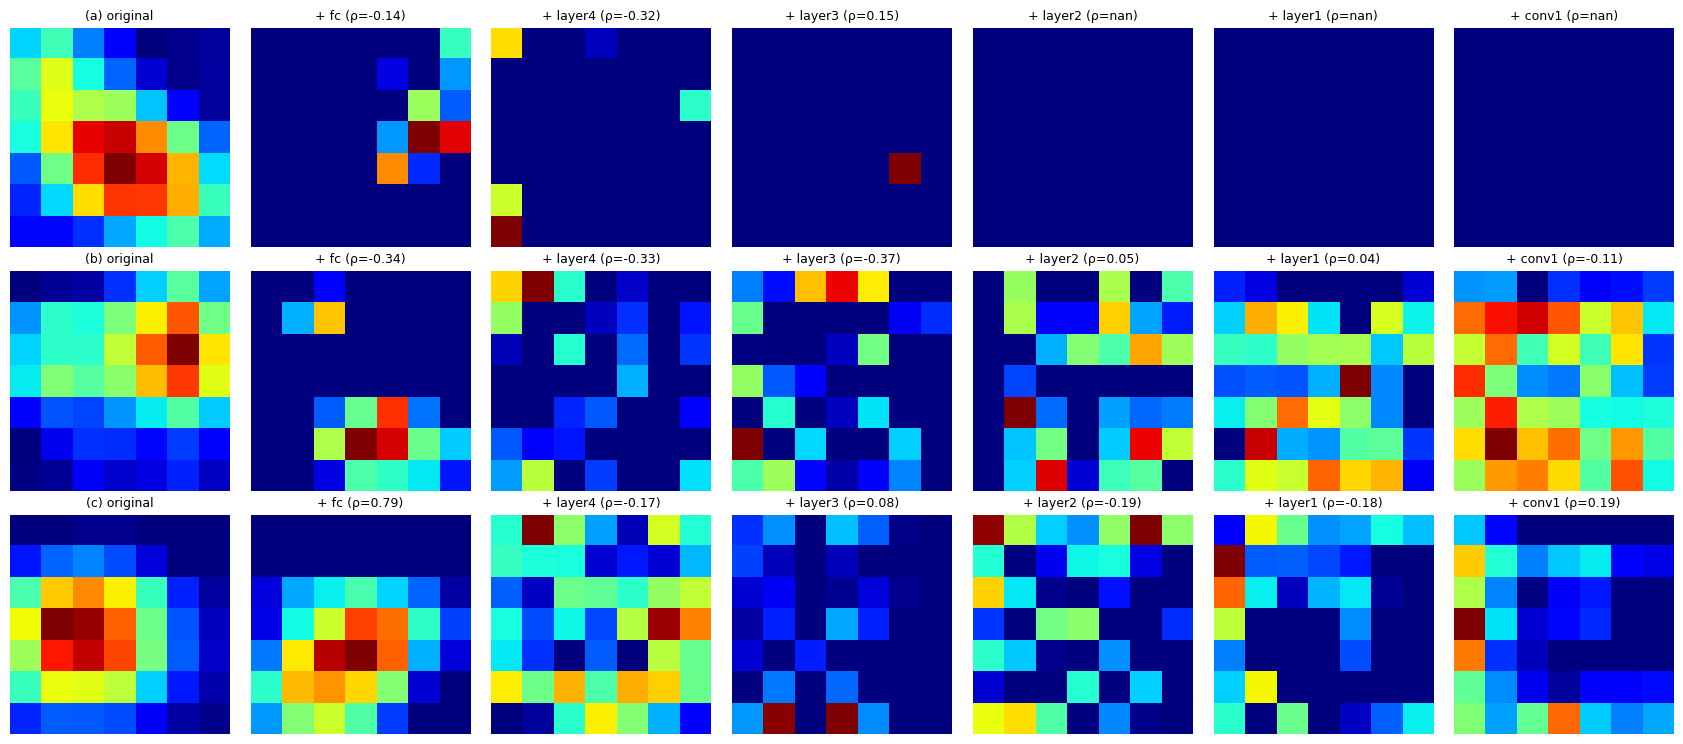

In [16]:
fig, axes = plt.subplots(3, 7, figsize=(17, 7.5))
for row, key in enumerate(keys):
    axes[row, 0].imshow(cams[key].cam, cmap="jet")
    axes[row, 0].set_title(f"({key}) original", fontsize=9)
    for s, stage in enumerate(CASCADE_STAGES):
        axes[row, s + 1].imshow(cascade_maps[s][row], cmap="jet")
        axes[row, s + 1].set_title(f"+ {stage} (ρ={rho[s, row]:.2f})", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

**RESULTADOS**

Al aleatorizar solo `fc`, el Spearman cae a -0.14 en la imagen (a) y a -0.34 en la imagen (b), mientras que en la imagen (c) se mantiene en 0.79. A partir de `layer4` ningún valor supera 0.2. En la imagen (a) los mapas de las etapas `layer2`, `layer1` y `conv1` son constantes (todos cero después de la ReLU), por lo que el Spearman no está definido y aparece como NaN.

### Task 4.3. Análisis con los resultados

#### 4.3.1. Distancia al azar y efecto de la referencia gris

Se expresa la ventaja de Grad-CAM sobre el azar en desviaciones estándar de la distribución aleatoria. En deletion la ventaja es $\frac{\bar{A}_{\text{azar}} - A_{\text{mapa}}}{s_{\text{azar}}}$ y en insertion es $\frac{A_{\text{mapa}} - \bar{A}_{\text{azar}}}{s_{\text{azar}}}$.

In [17]:
rows = []
for key in IMAGES:
    d, i = faith[key]["deletion"], faith[key]["insertion"]
    rows.append({
        "imagen": key,
        "deletion (desv. est. sobre el azar)": (d["random_aucs"].mean() - d["auc"]) / d["random_aucs"].std(ddof=1),
        "insertion (desv. est. sobre el azar)": (i["auc"] - i["random_aucs"].mean()) / i["random_aucs"].std(ddof=1),
    })
pd.DataFrame(rows).set_index("imagen")

,deletion (desv. est. sobre el azar),insertion (desv. est. sobre el azar)
imagen,,
a,5.60915,15.3796
b,6.41249,23.0653
c,1.67117,29.5303


Se repite deletion en la imagen (a) usando como referencia la versión desenfocada en lugar del gris medio.

In [18]:
del_blur = faithfulness_scores(model, inputs["a"], cams["a"].heatmap, top1["a"], rng, "deletion",
                               blurred_like(inputs["a"], 10.0), n_random=10, steps=20)
del_gray = faith["a"]["deletion"]
pd.DataFrame({
    "AUC_del Grad-CAM": [del_gray["auc"], del_blur["auc"]],
    "AUC_del azar (media)": [del_gray["random_aucs"].mean(), del_blur["random_aucs"].mean()],
    "AUC_del azar (desv. est.)": [del_gray["random_aucs"].std(ddof=1), del_blur["random_aucs"].std(ddof=1)],
}, index=pd.Index(["gris medio", "desenfocada"], name="referencia (imagen a)"))

,AUC_del Grad-CAM,AUC_del azar (media),AUC_del azar (desv. est.)
referencia (imagen a),,,
gris medio,0.125361,0.388451,0.0469037
desenfocada,0.154634,0.329011,0.0211672


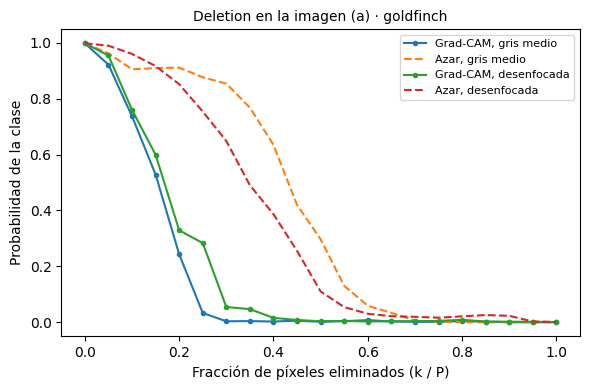

In [19]:
fig, ax = plt.subplots(figsize=(6, 4))
for label, r in (("gris medio", del_gray), ("desenfocada", del_blur)):
    ax.plot(fractions, r["curve"], marker="o", ms=3, label=f"Grad-CAM, {label}")
    ax.plot(fractions, r["random_curves"].mean(axis=0), ls="--", label=f"Azar, {label}")
ax.set_xlabel("Fracción de píxeles eliminados (k / P)")
ax.set_ylabel("Probabilidad de la clase")
ax.set_title(f"Deletion en la imagen (a) · {categories[top1['a']]}", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Respuesta**

Grad-CAM supera al azar en ambas métricas y en las tres imágenes. En deletion la ventaja es de 5.6, 6.4 y 1.7 desviaciones estándar en las imágenes (a), (b) y (c), y en insertion es de 15.4, 23.1 y 29.5. La ventaja menor está en deletion de la imagen (c), porque la probabilidad de `ox` parte de 0.45 y cualquier eliminación la lleva casi a cero en el primer paso (el azar obtiene un AUC de 0.015), de modo que queda poco margen para distinguir un buen orden.

La forma de las curvas refleja la resolución de 7 por 7. Cada paso modifica el 5% de los píxeles (2 509), algo más de dos celdas de 1 024 píxeles, y el orden dentro de cada mancha lo fija la interpolación bilineal y no una evidencia más fina. Por eso las curvas del mapa cambian a saltos grandes al principio. En la imagen (a), deletion lleva la probabilidad de 1.00 a 0.03 al eliminar el 25% de los píxeles, e insertion la sube a 0.98 con el 15%. Una vez insertado el objeto, las curvas de insertion de (b) y (c) dejan de ser monótonas (en (b) bajan de 0.85 a 0.64), porque las regiones de menor valor agregan contexto que compite con la clase, como el gato en la imagen (b). En insertion, las curvas aleatorias casi no se mueven hasta el 60% de los píxeles, ya que los píxeles sueltos no reconstruyen ninguna forma.

Con la referencia desenfocada, el $\operatorname{AUC}_{\text{del}}$ de Grad-CAM en la imagen (a) sube de 0.125 a 0.155, porque el desenfoque conserva los colores y la silueta del ave en las zonas eliminadas, mientras que el gris borra toda evidencia y además introduce bordes artificiales. Con órdenes aleatorios ocurre lo contrario (de 0.388 a 0.329), de modo que la referencia cambia la escala de ambas curvas de forma distinta. La ventaja de Grad-CAM se mantiene, con $\frac{0.329 - 0.155}{0.021} = 8.2$ desviaciones estándar frente a 5.6 con gris, pero el valor absoluto del AUC depende de la referencia y debe reportarse junto con ella.

#### 4.3.2. Etapa en que se pierde la correlación y predicción para `fc`

Se identifica la primera etapa en que el Spearman cae por debajo de 0.3 en cada imagen. Además, se reproduce la primera etapa (solo `fc` aleatorizada, con la misma semilla) para comparar los nuevos $a_{k}^{c}$ con $\frac{w_{k}^{c}}{Z}$ de la capa aleatoria y verificar si las activaciones $A$ cambian.

In [20]:
for col, key in enumerate(keys):
    below = np.flatnonzero(rho[:, col] < 0.3)
    stage = f"+ {CASCADE_STAGES[below[0]]}" if below.size else "ninguna"
    constant = [f"+ {s}" for s, maps in zip(CASCADE_STAGES, cascade_maps) if np.ptp(maps[col]) == 0]
    print(f"Imagen ({key}): primera etapa con Spearman < 0.3 -> {stage} | etapas con mapa constante: {constant or 'ninguna'}")

torch.manual_seed(SEED)
model_fc = copy.deepcopy(model).eval()
reset_module(model_fc.fc)
res_fc = grad_cam(model_fc, model_fc.layer4, inputs["a"], top1["a"])
w_rand = model_fc.fc.weight.detach()[top1["a"]].numpy()
print(f"\nImagen (a) con fc aleatoria:")
print(f"  max |A_aleatorio - A_original|       = {np.abs(res_fc.activations - cams['a'].activations).max():.3e}")
print(f"  max |a_k - w_k(aleatorio) / Z|        = {np.abs(res_fc.alpha - w_rand / Z).max():.3e}")
print(f"  Spearman(mapa original, mapa con fc) = {rho[0, 0]:.4f}")

Imagen (a): primera etapa con Spearman < 0.3 -> + fc | etapas con mapa constante: ['+ layer2', '+ layer1', '+ conv1']
Imagen (b): primera etapa con Spearman < 0.3 -> + fc | etapas con mapa constante: ninguna
Imagen (c): primera etapa con Spearman < 0.3 -> + layer4 | etapas con mapa constante: ninguna

Imagen (a) con fc aleatoria:
  max |A_aleatorio - A_original|       = 0.000e+00
  max |a_k - w_k(aleatorio) / Z|        = 1.746e-10
  Spearman(mapa original, mapa con fc) = -0.1408


**Respuesta**

El Spearman cae por debajo de 0.3 en la primera etapa (`fc`) en las imágenes (a) y (b), y en la segunda etapa (`layer4`) en la imagen (c).

Como $a_{k}^{c} = \frac{w_{k}^{c}}{Z}$, al aleatorizar solo `fc` las activaciones $A$ no cambian y los pesos de los canales pasan a ser $\frac{w_{k}^{\text{aleatorio}}}{Z}$. Se predice entonces que el mapa se convierte en la ReLU de una combinación aleatoria de los mismos 512 canales y pierde su relación con la clase. La salida confirma el mecanismo, ya que $A$ no cambia (diferencia máxima de 0) y $a_{k}^{c}$ coincide con $\frac{w_{k}^{\text{aleatorio}}}{Z}$ con un error de $1.7 \times 10^{-10}$. El resultado concuerda con la predicción en (a) y (b), con Spearman de -0.14 y -0.34. En (c) el Spearman sigue en 0.79 porque muchos canales de `layer4` se activan en la misma zona, la vaca, y una combinación aleatoria de canales que comparten una región dominante conserva esa región. Ese caso muestra que el mapa también refleja dónde son fuertes las activaciones y no solo la clase, por lo que la prueba debe continuar más allá de `fc`. En la imagen (a) los mapas llegan a ser constantes desde `layer2`, lo que confirma que el método sí depende de los pesos del modelo.

#### 4.3.3. Explicaciones del modelo de crédito para tres audiencias

Los números de esta respuesta provienen de [`02_tabular.ipynb`](./02_tabular.ipynb).

**Persona Solicitante**

Se entregaría un contrafactual accionable acompañado de las principales razones en lenguaje sencillo. Para el cliente rechazado, el contrafactual más cercano (distancia 2.20) reduce el plazo de 36 a 30 meses y el monto de 3 990 a 3 780, y la probabilidad de `good` sube de 0.087 a 0.530. La validación es que el propio modelo evalúa el contrafactual por encima de $\theta = 0.5$ y que solo cambia variables accionables, sin tocar `age`, `personal_status` ni `foreign_worker`. No se entregarían valores SHAP en log-odds ni coeficientes de LIME, y se revisaría la plausibilidad de cada cambio antes de comunicarlo. Por ejemplo, los dos primeros contrafactuales piden pasar a `no checking`, es decir, dejar de tener cuenta corriente, lo que no es una recomendación razonable aunque el modelo la premie.

**Oficial de Cumplimiento Interno**

Se entregarían las cascadas SHAP de cada decisión y la importancia global. Las validaciones son el error de eficiencia de $9.7 \times 10^{-8}$, la coincidencia del valor base con el promedio sobre el fondo (1.430742 en ambos casos) y el error de $2.1 \times 10^{-8}$ frente al cálculo exacto con la fórmula de Shapley. También se le señalarían los puntos que requieren revisión, como `age`, que es la sexta variable por $I_{j}$ pero no aporta AUC al barajarla y que aparece entre las cinco variables de LIME del cliente rechazado. No se entregaría LIME como explicación principal, porque su fidelidad es baja ($R_{w}^{2} = 0.23$ con $K = 5$ y 0.30 con $K = 20$) y es inestable con pocas muestras (Jaccard de 0.63 con $N = 500$).

**Regulador**

Se entregaría la documentación del método y de su validación a nivel global, con el desempeño del modelo (exactitud de 0.775 y AUC de 0.765), la importancia global por SHAP y por permutación con su correlación (Spearman de 0.65), las pruebas de exactitud de SHAP, la concordancia de KernelSHAP con TreeSHAP (MAE menor que 0.006), las tablas de estabilidad de LIME y las limitaciones conocidas, como la codificación ordinal arbitraria y el reparto del crédito entre variables correlacionadas del Task 2.3. No se entregarían explicaciones individuales con datos personales salvo que se soliciten, ni explicaciones sin su validación.

**Detección de Lavado**

En un sistema de detección de lavado como el del Proyecto 2, un contrafactual le dice a quien comete el delito exactamente qué cambiar para quedar por debajo del umbral de alerta. En el Task 3.4 bastaron tres cambios para cruzar el umbral, y la búsqueda de 20 000 candidatos encontró 16 caminos válidos, cualquiera de los cuales serviría como receta de evasión si la persona investigada pudiera verlo. En su lugar, a la persona afectada se le entregarían solo categorías generales del motivo de la revisión, sin umbrales ni valores, y a los analistas y al regulador se les entregarían explicaciones SHAP internas con acceso controlado, junto con la validación del modelo.